In [2]:
from sklearn.datasets import load_diabetes
import pandas as pd

# 1. 加载数据
diabetes = load_diabetes()

# 2. 提取特征和目标变量
X = diabetes.data
y = diabetes.target

# 3. 查看数据基本信息
print("========== Diabetes 数据集 ==========")
print("特征矩阵形状：", X.shape)
print("目标变量形状：", y.shape)
print("特征名称：", diabetes.feature_names)

# 4. 转换成 Pandas 表格
df = pd.DataFrame(
    X,
    columns=diabetes.feature_names
)

df["target"] = y

# 5. 显示前5条数据
print("\n========== 前5条数据 ==========")
display(df.head())

========== Diabetes 数据集 ==========
特征矩阵形状： (442, 10)
目标变量形状： (442,)
特征名称： ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

========== 前5条数据 ==========


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


========== 目标变量统计信息 ==========
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

========== 缺失值数量 ==========
0


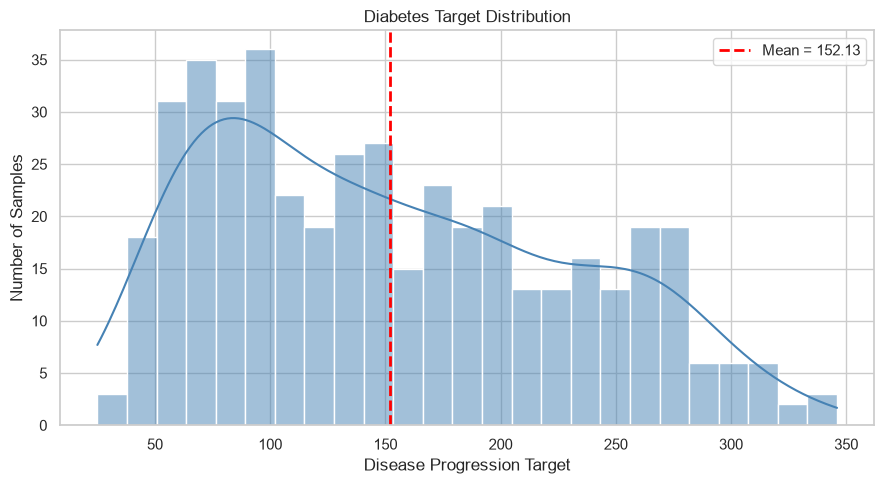


图片保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\09_diabetes_target_distribution.png


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. 查看目标变量的统计信息
print("========== 目标变量统计信息 ==========")
print(df["target"].describe())

print("\n========== 缺失值数量 ==========")
print(df["target"].isnull().sum())

# 2. 设置绘图风格
sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

# 3. 绘制目标变量分布直方图
sns.histplot(
    data=df,
    x="target",
    bins=25,
    kde=True,
    color="steelblue"
)

# 4. 添加均值参考线
target_mean = df["target"].mean()

plt.axvline(
    target_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {target_mean:.2f}"
)

plt.title("Diabetes Target Distribution")
plt.xlabel("Disease Progression Target")
plt.ylabel("Number of Samples")
plt.legend()
plt.tight_layout()

# 5. 设置图片保存目录
project_root = Path(
    r"D:\AI-Internship\Week01_AI_Basic_Iris_Regression"
)

figure_dir = project_root / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# 6. 保存图片
figure_path = figure_dir / "09_diabetes_target_distribution.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n图片保存成功！")
print("保存路径：", figure_path)

========== Diabetes 相关系数矩阵 ==========


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.00,0.17,0.19,0.34,0.26,0.22,-0.08,0.20,0.27,0.30,0.19
sex,0.17,1.00,0.09,0.24,0.04,0.14,-0.38,0.33,0.15,0.21,0.04
bmi,0.19,0.09,1.00,0.40,0.25,0.26,-0.37,0.41,0.45,0.39,0.59
bp,0.34,0.24,0.40,1.00,0.24,0.19,-0.18,0.26,0.39,0.39,0.44
s1,0.26,0.04,0.25,0.24,1.00,0.90,0.05,0.54,0.52,0.33,0.21
s2,0.22,0.14,0.26,0.19,0.90,1.00,-0.20,0.66,0.32,0.29,0.17
s3,-0.08,-0.38,-0.37,-0.18,0.05,-0.20,1.00,-0.74,-0.40,-0.27,-0.39
s4,0.20,0.33,0.41,0.26,0.54,0.66,-0.74,1.00,0.62,0.42,0.43
s5,0.27,0.15,0.45,0.39,0.52,0.32,-0.40,0.62,1.00,0.46,0.57
s6,0.30,0.21,0.39,0.39,0.33,0.29,-0.27,0.42,0.46,1.00,0.38



========== 各特征与 target 的相关性 ==========


bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s3    -0.3948
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
Name: target, dtype: float64

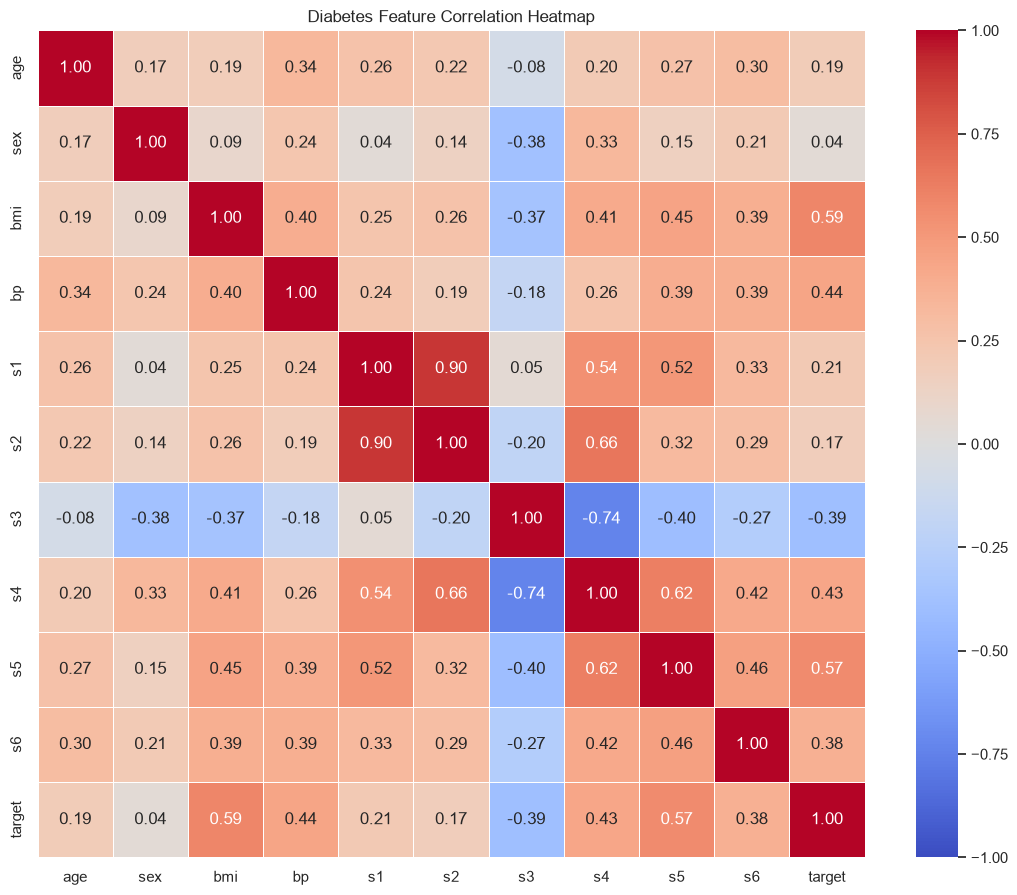

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\10_diabetes_correlation_heatmap.png


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 计算相关系数矩阵
correlation_matrix = df.corr()

print("========== Diabetes 相关系数矩阵 ==========")
display(correlation_matrix.round(2))

# 2. 提取各特征与 target 的相关性
target_correlation = correlation_matrix["target"].drop("target")

# 按相关系数绝对值从大到小排序
target_correlation = target_correlation.reindex(
    target_correlation.abs().sort_values(ascending=False).index
)

print("\n========== 各特征与 target 的相关性 ==========")
display(target_correlation.round(4))

# 3. 绘制相关性热力图
plt.figure(figsize=(11, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Diabetes Feature Correlation Heatmap")
plt.tight_layout()

# 4. 保存图片
figure_path = figure_dir / "10_diabetes_correlation_heatmap.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("保存成功！")
print("保存路径：", figure_path)

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd

# 1. 准备特征和目标变量
X = df.drop(columns=["target"])
y = df["target"]

# 2. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("========== 数据集划分 ==========")
print("训练集特征：", X_train.shape)
print("测试集特征：", X_test.shape)
print("训练集目标：", y_train.shape)
print("测试集目标：", y_test.shape)

# 3. 创建线性回归模型
lr_reg_model = LinearRegression()

# 4. 训练模型
lr_reg_model.fit(X_train, y_train)

# 5. 预测测试集
y_pred_lr_reg = lr_reg_model.predict(X_test)

print("\n========== Linear Regression ==========")
print("模型训练成功！")
print("预测结果数量：", len(y_pred_lr_reg))

# 6. 对比前10条真实值与预测值
comparison_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_lr_reg
})

print("\n========== 前10条预测结果 ==========")
display(comparison_df.head(10))

========== 数据集划分 ==========
训练集特征： (353, 10)
测试集特征： (89, 10)
训练集目标： (353,)
测试集目标： (89,)

========== Linear Regression ==========
模型训练成功！
预测结果数量： 89

========== 前10条预测结果 ==========


,Actual,Predicted
0,219.0,139.547558
1,70.0,179.517208
2,202.0,134.038756
3,230.0,291.417029
4,111.0,123.789659
5,84.0,92.172347
6,242.0,258.232389
7,272.0,181.337321
8,94.0,90.224113
9,96.0,108.633759


In [6]:
from sklearn.linear_model import Ridge
import pandas as pd

# 1. 创建 Ridge 模型
ridge_model = Ridge(alpha=1.0)

# 2. 使用相同训练集训练
ridge_model.fit(X_train, y_train)

# 3. 预测相同测试集
y_pred_ridge = ridge_model.predict(X_test)

print("========== Ridge Regression ==========")
print("模型名称：Ridge Regression")
print("alpha：", ridge_model.alpha)
print("训练样本数量：", len(X_train))
print("测试样本数量：", len(X_test))
print("预测结果数量：", len(y_pred_ridge))

# 4. 比较前10条预测结果
ridge_comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Linear Regression": y_pred_lr_reg,
    "Ridge Regression": y_pred_ridge
})

print("\n========== 前10条预测结果对比 ==========")
display(ridge_comparison.head(10))

========== Ridge Regression ==========
模型名称：Ridge Regression
alpha： 1.0
训练样本数量： 353
测试样本数量： 89
预测结果数量： 89

========== 前10条预测结果对比 ==========


,Actual,Linear Regression,Ridge Regression
0,219.0,139.547558,157.285470
1,70.0,179.517208,163.007787
2,202.0,134.038756,155.180153
3,230.0,291.417029,247.348267
4,111.0,123.789659,143.866166
5,84.0,92.172347,126.295728
6,242.0,258.232389,218.146858
7,272.0,181.337321,190.207607
8,94.0,90.224113,113.852176
9,96.0,108.633759,134.559786


对比

In [7]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. 定义评价函数
def evaluate_regression(y_true, y_pred):

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    mae = mean_absolute_error(y_true, y_pred)

    r2 = r2_score(y_true, y_pred)

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }


# 2. 评价 Linear Regression
lr_metrics = evaluate_regression(
    y_test,
    y_pred_lr_reg
)

# 3. 评价 Ridge Regression
ridge_metrics = evaluate_regression(
    y_test,
    y_pred_ridge
)


# 4. 创建模型对比表
regression_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        **lr_metrics
    },
    {
        "Model": "Ridge Regression",
        **ridge_metrics
    }
])

print("========== 回归模型评价结果 ==========")

display(regression_results.round(4))


# 5. 保存为 CSV
csv_path = (
    project_root
    / "results"
    / "diabetes_regression_model_comparison.csv"
)

regression_results.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n模型评价表保存成功！")
print("保存路径：", csv_path)

========== 回归模型评价结果 ==========


,Model,MSE,RMSE,MAE,R2
0,Linear Regression,2900.1936,53.8534,42.7941,0.4526
1,Ridge Regression,3077.4159,55.4745,46.1389,0.4192



模型评价表保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\diabetes_regression_model_comparison.csv


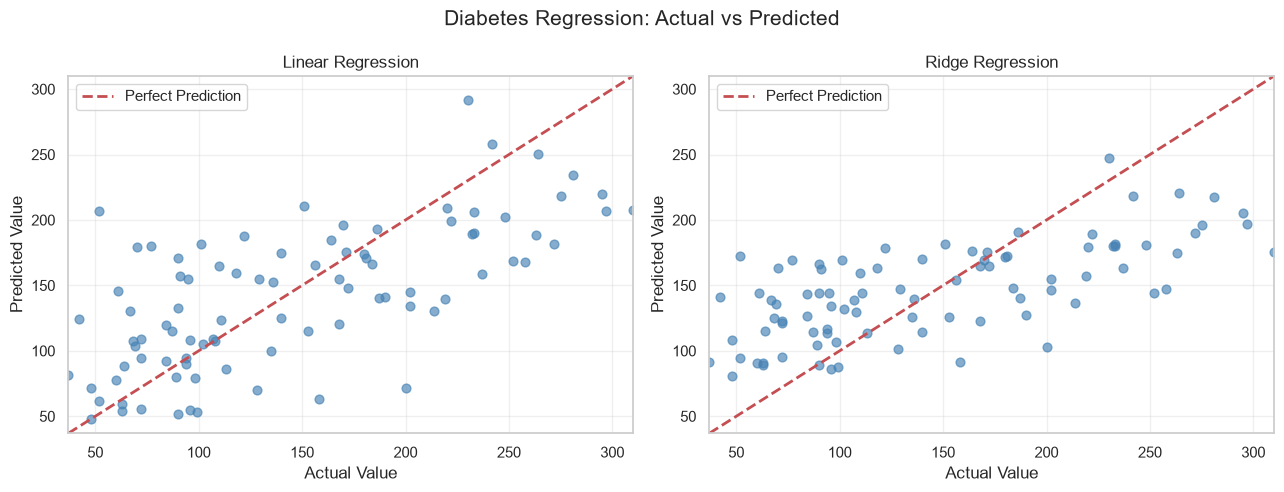

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\11_diabetes_actual_vs_predicted.png


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# 创建左右两个子图
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 两个模型的预测结果
predictions = [
    ("Linear Regression", y_pred_lr_reg),
    ("Ridge Regression", y_pred_ridge)
]

# 统一横纵轴范围，确保比较公平
all_values = np.concatenate([
    y_test.to_numpy(),
    y_pred_lr_reg,
    y_pred_ridge
])

min_value = all_values.min()
max_value = all_values.max()

for ax, (model_name, y_pred) in zip(axes, predictions):

    # 绘制真实值与预测值散点
    ax.scatter(
        y_test,
        y_pred,
        alpha=0.65,
        s=40,
        color="steelblue"
    )

    # 绘制理想预测线 y=x
    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        "r--",
        linewidth=2,
        label="Perfect Prediction"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual Value")
    ax.set_ylabel("Predicted Value")

    ax.set_xlim(min_value, max_value)
    ax.set_ylim(min_value, max_value)

    ax.legend()
    ax.grid(True, alpha=0.3)

# 总标题
fig.suptitle(
    "Diabetes Regression: Actual vs Predicted",
    fontsize=15
)

plt.tight_layout()

# 保存图片
figure_path = (
    figure_dir
    / "11_diabetes_actual_vs_predicted.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("保存成功！")
print("保存路径：", figure_path)